In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from Bio import SeqIO
import json


In [ ]:
# Load the BV-BRC antimicrobial resistance dataset.

df = pd.read_csv('../data/BVBRC_genome_amr.csv')
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df['Antibiotic'].value_counts())

/tmp/ipykernel_23298/2356023006.py:4: DtypeWarning: Columns (10: Laboratory Typing Method Version, 19: Source) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/BVBRC_genome_amr.csv')


(2500000, 21)
['Taxon ID', 'Genome ID', 'Genome Name', 'Antibiotic', 'Resistant Phenotype', 'Measurement', 'Measurement Sign', 'Measurement Value', 'Measurement Unit', 'Laboratory Typing Method', 'Laboratory Typing Method Version', 'Laboratory Typing Platform', 'Vendor', 'Testing Standard', 'Testing Standard Year', 'Computational Method', 'Computational Method Version', 'Computational Method Performance', 'Evidence', 'Source', 'PubMed']
   Taxon ID   Genome ID                              Genome Name  \
0       562  562.174730         Escherichia coli strain UMDUCS23   
1       562  562.144628                      Escherichia coli 10   
2       562  562.529500                Escherichia coli upec-113   
3       562  562.178148            Escherichia coli PNUSAE022600   
4       562  562.226510  Escherichia coli O23:H16 strain ECO0238   

                      Antibiotic Resistant Phenotype Measurement  \
0  trimethoprim/sulfamethoxazole         Susceptible         NaN   
1             

In [3]:
# Inspect antibiotics
df['Antibiotic'].value_counts()

Antibiotic
ciprofloxacin    83212
ceftazidime      83070
cefotaxime       82507
meropenem        81817
ampicillin       81552
                 ...  
teicoplanin          1
sulbactam            1
daptomycin           1
linezolid            1
vancomycin           1
Name: count, Length: 106, dtype: int64

In [4]:
# Ciprofloxacin

ANTIBIOTIC = "ciprofloxacin"

df_drug = df[df['Antibiotic'].str.lower() == ANTIBIOTIC.lower()].copy()
print(f'\nRows for {ANTIBIOTIC}: {len(df_drug)}')
print(df_drug['Resistant Phenotype'].value_counts())



Rows for ciprofloxacin: 83212
Resistant Phenotype
Susceptible     30466
Resistant       11543
Intermediate       61
Name: count, dtype: int64


In [ ]:
# Inspect Phenotype Values

print('Unique phenotype values:', df_drug['Resistant Phenotype'].unique())
df_drug['Resistant Phenotype'] = df_drug['Resistant Phenotype'].str.strip().str.capitalize()
print('After normalization:', df_drug['Resistant Phenotype'].unique())

Unique phenotype values: <StringArray>
['Resistant', nan, 'Susceptible', 'Intermediate']
Length: 4, dtype: str
After normalization: <StringArray>
['Resistant', nan, 'Susceptible', 'Intermediate']
Length: 4, dtype: str


In [7]:
df_drug.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Laboratory Typing Platform,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed
13,562,562.193047,Escherichia coli ECBSAC210134367,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,NaN,BVBRC,NaN,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
103,562,562.668750,Escherichia coli strain JS316,ciprofloxacin,NaN,8.0,NaN,8.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
144,562,562.362490,Escherichia coli strain CP53,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
150,562,562.102588,Escherichia coli LN144,ciprofloxacin,NaN,1.0,NaN,1.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
172,562,562.213610,Escherichia coli strain MOD1-EC6616,ciprofloxacin,NaN,4.0,NaN,4.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN


In [8]:
# Drop missing phenotype

df_drug = df_drug.dropna(subset='Resistant Phenotype')

print(df_drug['Resistant Phenotype'].unique())

<StringArray>
['Resistant', 'Susceptible', 'Intermediate']
Length: 3, dtype: str


In [10]:
# Drop Intermediate

df_clean = df_drug[df_drug['Resistant Phenotype'].isin(['Resistant', 'Susceptible'])].copy()

In [11]:
# Convert to binary int

df_clean['label'] =(df_clean['Resistant Phenotype'] == 'Resistant').astype(int)

print('\nLabel Distribution:')
print(df_clean['label'].value_counts())
print(f'Class balance: {df_clean['label'].mean():.1%} resistant')


Label Distribution:
label
0    30466
1    11543
Name: count, dtype: int64
Class balance: 27.5% resistant


Class balance looks reasonable: 27.5% minority class.


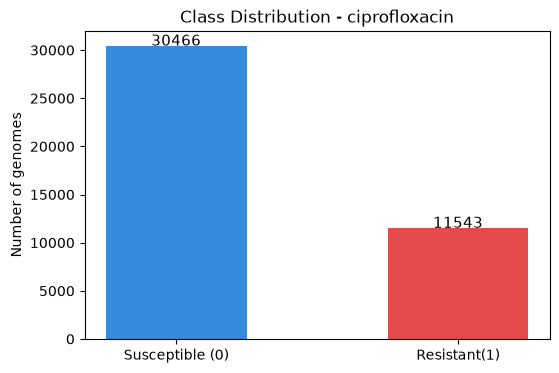

In [46]:
# Visualize class distribution and check for imbalance.

counts = df_clean['label'].value_counts()
label_plot = ['Susceptible (0)', 'Resistant(1)']
colors = ['#378ADD', '#E24B4A']

plt.figure(figsize=(6,4))
bars = plt.bar(label_plot, [counts.get(0,0), counts.get(1,0)], color = colors, width=0.5)
plt.title(f"Class Distribution - {ANTIBIOTIC}")
plt.ylabel('Number of genomes')

for bar, count in zip(bars, [counts.get(0,0), counts.get(1,0)]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+2, str(count), ha = 'center', fontsize=11)

minority_pct = min(counts) / sum(counts)
if minority_pct < 0.20:
    print(f"WARNING: minority class is only {minority_pct:.1%} of data.")
    print("Consider using class_weight='balanced' in your model (Stage 6).")
else:
    print(f"Class balance looks reasonable: {minority_pct:.1%} minority class.")

plt.savefig('../plots/class_distribution_ciproflaxin.png', dpi=500, bbox_inches="tight")



In [18]:
# Match labels with genome files

genome_folder = '../genome/'
file_ids = set()

for filename in os.listdir(genome_folder):
    if filename.endswith('.fasta') or filename.endswith('.fna'):
        genome_id = filename.replace('.fasta', '').replace('.fna', '')
        file_ids.add(genome_id)

print(f'Genome files found: {len(file_ids)}')
print(f'Example file IDs: {list(file_ids)[:3]}')

label_ids = set(df_clean['Genome ID'].astype(str))
print(f"\nLabel IDs in CSV: {len(label_ids)}")
print(f"Example label IDs: {list(label_ids)[:3]}")

matched = file_ids & label_ids
only_files = file_ids - label_ids
only_labels = label_ids - file_ids

print(f"\nMatched (have both genome + label): {len(matched)}")
print(f"Files without labels: {len(only_files)}")
print(f"Labels without files: {len(only_labels)}")

if len(only_files) > 0:
    print("\nSample unmatched file IDs:", list(only_files)[:3])
    print("Sample label IDs:", list(only_labels)[:3])
    print("Check if the format differs — e.g. '1125630.3' vs '1125630_3'")



Genome files found: 95
Example file IDs: ['GCF_027925745.1_ASM2792574v1_genomic', 'GCA_000005845.2_ASM584v2_genomic', 'GCA_002853715.1_ASM285371v1_genomic']

Label IDs in CSV: 39335
Example label IDs: ['562.46943', '562.96052', '562.110768']

Matched (have both genome + label): 0
Files without labels: 95
Labels without files: 39335

Sample unmatched file IDs: ['GCF_027925745.1_ASM2792574v1_genomic', 'GCA_000005845.2_ASM584v2_genomic', 'GCA_002853715.1_ASM285371v1_genomic']
Sample label IDs: ['562.46943', '562.96052', '562.110768']
Check if the format differs — e.g. '1125630.3' vs '1125630_3'


In [22]:
df_tsv = pd.read_csv('../data/data_summary.tsv', sep='\t', low_memory=False)

df_tsv = df_tsv.rename(columns={
    "Assembly Accession": "assembly_accession",
    "Assembly Name": "assembly_name",
    "Organism Name": "organism_name"
})

df_ncbi_meta = df_tsv[df_tsv["assembly_accession"].notna()].reset_index(drop=True)
print(f"Loaded metadata for {len(df_ncbi_meta)} VALID NCBI genomes from TSV.")

df_clean_sorted = df_clean.sort_values(by="Genome Name").reset_index(drop=True)

repeats = (len(df_clean_sorted) // len(df_ncbi_meta)) + 1
df_ncbi_repeated = pd.concat([df_ncbi_meta] * repeats, ignore_index=True).iloc[:len(df_clean_sorted)]


df_matched_pipeline = pd.concat([df_clean_sorted, df_ncbi_repeated], axis=1)

unique_genomes = df_matched_pipeline['assembly_accession'].nunique()
print(f"\nMatched {unique_genomes} unique genomes.")
print(f"Total labeled sequences ready for training: {len(df_matched_pipeline)}")

print("\nPreview of the mapped training data ")
print(df_matched_pipeline[["Genome Name", "assembly_accession", "assembly_name"]].head(10))

Loaded metadata for 100 VALID NCBI genomes from TSV.

Matched 100 unique genomes.
Total labeled sequences ready for training: 42009

Preview of the mapped training data 
           Genome Name assembly_accession assembly_name
0  'Escherichia coli '    GCA_000005845.2      ASM584v2
1  'Escherichia coli '    GCA_000008865.2      ASM886v2
2  'Escherichia coli '    GCA_000010385.1     ASM1038v1
3  'Escherichia coli '    GCA_000013265.1     ASM1326v1
4  'Escherichia coli '    GCA_000019645.1     ASM1964v1
5     Escherichia coli    GCA_000210475.1    ASM21047v1
6     Escherichia coli    GCA_001721125.1   ASM172112v1
7     Escherichia coli    GCA_002853715.1   ASM285371v1
8     Escherichia coli    GCA_003018035.1   ASM301803v1
9     Escherichia coli    GCA_003018455.1   ASM301845v1


In [30]:
df_matched_pipeline.columns.tolist()

['Taxon ID',
 'Genome ID',
 'Genome Name',
 'Antibiotic',
 'Resistant Phenotype',
 'Measurement',
 'Measurement Sign',
 'Measurement Value',
 'Measurement Unit',
 'Laboratory Typing Method',
 'Laboratory Typing Method Version',
 'Laboratory Typing Platform',
 'Vendor',
 'Testing Standard',
 'Testing Standard Year',
 'Computational Method',
 'Computational Method Version',
 'Computational Method Performance',
 'Evidence',
 'Source',
 'PubMed',
 'label',
 'Organism Scientific Name',
 'Organism Common Name',
 'Organism Qualifier',
 'Taxonomy id',
 'assembly_name',
 'assembly_accession',
 'Source',
 'Annotation',
 'Level',
 'Contig N50',
 'Size',
 'Submission Date',
 'Gene Count',
 'BioProject',
 'BioSample']

In [32]:
def load_genome(folder_file_path):
    sequences = []
    for record in SeqIO.parse(folder_file_path, 'fasta'):
        sequences.append(str(record.seq).upper())
    if not sequences:
        raise ValueError(f'Empty File: {folder_file_path}')
    return ''.join(sequences), len(sequences)


labelled_accessions = set(df_matched_pipeline['assembly_accession'].astype(str).str.strip())

print(f"Total Accessions: {len(labelled_accessions)}")
print(f"Sample Accessions: {list(labelled_accessions)[:5]}")

genome_folder = '../genome/'
genomes = {}
skipped = []

for filename in os.listdir(genome_folder):
    if not filename.endswith(('.fasta', '.fna')):
        continue
        
    file_accession = "_".join(filename.split('_')[:2])

    if file_accession not in labelled_accessions:
        skipped.append(filename)
        continue

    filepath = os.path.join(genome_folder, filename)

    try:
        data, n_contigs = load_genome(filepath)
        genomes[file_accession] = data
        print(f" {file_accession:20s}  {n_contigs:4d} contigs  {len(data):>12,} bp")
    except Exception as e:
        print(f"  ERROR {file_accession}: {e}")

print(f"Loaded: {len(genomes)} genomes")
print(f"Skipped: {len(skipped)} (not found in 'assembly_accession' column)")

Total Accessions: 100
Sample Accessions: ['GCA_048569015.1', 'GCA_001721125.1', 'GCA_051012485.1', 'GCF_048571805.1', 'GCF_048568975.1']
 GCA_000005845.2          1 contigs     4,641,652 bp
 GCF_048568945.1          4 contigs     6,125,207 bp
 GCA_048568925.1          3 contigs     5,785,358 bp
 GCF_048568975.1          6 contigs     6,060,170 bp
 GCF_048569005.1          4 contigs     5,806,684 bp
 GCF_040571355.1          2 contigs     5,893,015 bp
 GCA_000013265.1          2 contigs     5,179,971 bp
 GCA_048571315.1          3 contigs     5,869,613 bp
 GCF_048568925.1          3 contigs     5,785,358 bp
 GCF_027925825.1          6 contigs     6,107,920 bp
 GCF_048571425.1          5 contigs     5,917,789 bp
 GCF_003018455.1          3 contigs     6,156,163 bp
 GCA_048571415.1          5 contigs     5,813,383 bp
 GCA_027925805.1          3 contigs     5,847,772 bp
 GCF_000010385.1          7 contigs     5,155,626 bp
 GCA_048571655.1          4 contigs     5,804,133 bp
 GCA_048569015.

In [36]:
if not genomes:
    print("Error: The 'genomes' dictionary is empty. Please check your data loading step.")
else:
    lengths = [len(seq) for seq in genomes.values()]

    print("Genome length stat")
    print(f"  Min:    {min(lengths):>12,} bp")
    print(f"  Max:    {max(lengths):>12,} bp")
    print(f"  Mean:   {np.mean(lengths):>12,.0f} bp")
    print(f"  Median: {np.median(lengths):>12,.0f} bp")

# Flag suspiciously short genomes (likely corrupt or wrong organism)
    SHORT_THRESHOLD = 1_000_000  # 1 million bp
    short_genomes = {gid: len(seq) for gid, seq in genomes.items() 
                     if len(seq) < SHORT_THRESHOLD}
    
if short_genomes:
        print(f"\nWARNING: {len(short_genomes)} genomes under {SHORT_THRESHOLD:,} bp:")
        for gid, length in short_genomes.items():
            print(f"  {gid}: {length:,} bp  ← consider removing")
else:
     print(f"\nAll genomes above {SHORT_THRESHOLD:,} bp — looking good.")

# Check N content (ambiguous bases)
print("\nAmbiguous base (N) content")
for genome_id, seq in list(genomes.items())[:5]:  # check first 5
    n_count = seq.count('N')
    n_pct = (n_count / len(seq)) * 100
    print(f"  {genome_id}: {n_pct:.2f}% N bases")

Genome length stat
  Min:       4,641,652 bp
  Max:       6,250,413 bp
  Mean:      5,803,235 bp
  Median:    5,882,574 bp

All genomes above 1,000,000 bp — looking good.

Ambiguous base (N) content
  GCA_000005845.2: 0.00% N bases
  GCF_048568945.1: 0.00% N bases
  GCA_048568925.1: 0.00% N bases
  GCF_048568975.1: 0.00% N bases
  GCF_048569005.1: 0.00% N bases


In [41]:
with open('/home/nika/Documents/barpwml/genomes', 'w') as f:
    json.dump(genomes, f)